In [ ]:
import random
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset, Subset
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", device)


PyTorch: 2.11.0+cpu
Device: cpu


In [ ]:
# Tensors
a = torch.tensor([[1.0, 2.0], [3.0, 4.0]])
b = torch.ones((2, 2))
print("a =\n", a)
print("a + b =\n", a + b)
print("Shape:", a.shape)

# Autograd example: y = x^2 + 3x
x = torch.tensor(2.0, requires_grad=True)
y = x**2 + 3*x
y.backward()
print("y =", y.item())
print("dy/dx =", x.grad.item(), "(expected 2*x + 3 = 7)")


a =
 tensor([[1., 2.],
        [3., 4.]])
a + b =
 tensor([[2., 3.],
        [4., 5.]])
Shape: torch.Size([2, 2])
y = 10.0
dy/dx = 7.0 (expected 2*x + 3 = 7)


In [ ]:
# Train a tiny neural network to learn y = 2x + 1
X = torch.linspace(-2, 2, 200).reshape(-1, 1)
y = 2 * X + 1 + 0.1 * torch.randn_like(X)

model = nn.Sequential(nn.Linear(1, 16), nn.ReLU(), nn.Linear(16, 1)).to(device)
X, y = X.to(device), y.to(device)
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.03)

for epoch in range(101):
    model.train()
    predictions = model(X)
    loss = loss_fn(predictions, y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    if epoch % 20 == 0:
        print(f"Epoch {epoch:3d} | loss = {loss.item():.4f}")

model.eval()
with torch.no_grad():
    print("Prediction for x=3:", model(torch.tensor([[3.0]], device=device)).item())


Epoch   0 | loss = 7.2560
Epoch  20 | loss = 0.5752
Epoch  40 | loss = 0.0418
Epoch  60 | loss = 0.0181
Epoch  80 | loss = 0.0118
Epoch 100 | loss = 0.0111
Prediction for x=3: 6.739798545837402


100%|██████████| 26.4M/26.4M [00:02<00:00, 10.2MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 154kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.06MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 10.3MB/s]


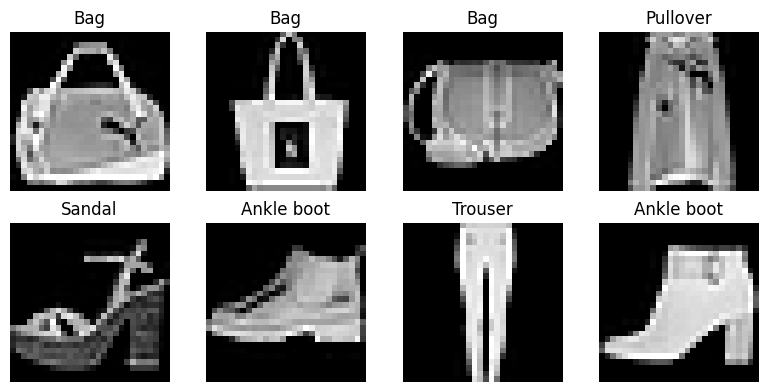

In [ ]:
from torchvision import datasets, transforms

transform = transforms.ToTensor()
train_ds = datasets.FashionMNIST(root="./data", train=True, download=True, transform=transform)
test_ds = datasets.FashionMNIST(root="./data", train=False, download=True, transform=transform)

# Smaller subset keeps this first run manageable; increase sizes for a more thorough experiment.
train_ds = Subset(train_ds, range(12000))
test_ds = Subset(test_ds, range(3000))
train_loader = DataLoader(train_ds, batch_size=128, shuffle=True)
test_loader = DataLoader(test_ds, batch_size=256, shuffle=False)

class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

images, labels = next(iter(train_loader))
plt.figure(figsize=(8, 4))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(images[i].squeeze(), cmap="gray")
    plt.title(class_names[labels[i]])
    plt.axis("off")
plt.tight_layout()
plt.show()


In [ ]:
class FashionCNN(nn.Module):
    def __init__(self, use_regularization=True):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32) if use_regularization else nn.Identity(),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64) if use_regularization else nn.Identity(),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(0.3) if use_regularization else nn.Identity(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

def evaluate(model, loader):
    model.eval()
    total, correct, loss_sum = 0, 0, 0.0
    criterion = nn.CrossEntropyLoss()
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss_sum += criterion(logits, yb).item() * yb.size(0)
            correct += (logits.argmax(1) == yb).sum().item()
            total += yb.size(0)
    return loss_sum / total, correct / total

def train_classifier(model, train_loader, val_loader, epochs=4, patience=2):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    best_val_loss = float("inf")
    best_state = None
    wait = 0
    history = {"train_loss": [], "val_loss": [], "val_acc": []}

    for epoch in range(epochs):
        model.train()
        running_loss, seen = 0.0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * yb.size(0)
            seen += yb.size(0)

        train_loss = running_loss / seen
        val_loss, val_acc = evaluate(model, val_loader)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        print(f"Epoch {epoch+1}/{epochs} | train loss {train_loss:.4f} | "
              f"val loss {val_loss:.4f} | val accuracy {val_acc:.3f}")

        # Early stopping: keep the model with the lowest validation loss.
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                print("Early stopping triggered.")
                break

    if best_state is not None:
        model.load_state_dict(best_state)
    return model, history

cnn = FashionCNN(use_regularization=True)
cnn, cnn_history = train_classifier(cnn, train_loader, test_loader, epochs=4, patience=2)


Epoch 1/4 | train loss 0.6798 | val loss 0.4445 | val accuracy 0.847
Epoch 2/4 | train loss 0.4235 | val loss 0.3786 | val accuracy 0.877
Epoch 3/4 | train loss 0.3554 | val loss 0.3494 | val accuracy 0.878
Epoch 4/4 | train loss 0.3123 | val loss 0.3455 | val accuracy 0.871


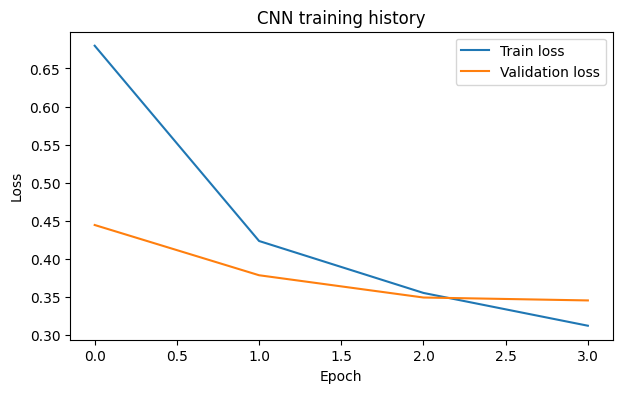

Fashion-MNIST subset test loss: 0.3455
Fashion-MNIST subset accuracy: 87.07%


In [ ]:
plt.figure(figsize=(7, 4))
plt.plot(cnn_history["train_loss"], label="Train loss")
plt.plot(cnn_history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN training history")
plt.legend()
plt.show()

test_loss, test_acc = evaluate(cnn, test_loader)
print(f"Fashion-MNIST subset test loss: {test_loss:.4f}")
print(f"Fashion-MNIST subset accuracy: {test_acc:.2%}")


In [ ]:
# Optional comparison: CNN without dropout and batch normalization
# This may take a few minutes. Compare with the regularized CNN above.
cnn_no_reg = FashionCNN(use_regularization=False)
cnn_no_reg, no_reg_history = train_classifier(
    cnn_no_reg, train_loader, test_loader, epochs=4, patience=2
)
print("Regularized accuracy:", f"{evaluate(cnn, test_loader)[1]:.2%}")
print("No-regularization accuracy:", f"{evaluate(cnn_no_reg, test_loader)[1]:.2%}")


Epoch 1/4 | train loss 0.8783 | val loss 0.5640 | val accuracy 0.791
Epoch 2/4 | train loss 0.4991 | val loss 0.4463 | val accuracy 0.847
Epoch 3/4 | train loss 0.4180 | val loss 0.4008 | val accuracy 0.861
Epoch 4/4 | train loss 0.3764 | val loss 0.3898 | val accuracy 0.858
Regularized accuracy: 87.07%
No-regularization accuracy: 85.80%


In [ ]:
# Create sequences from a sine wave: first 20 values -> next value
t = np.linspace(0, 80, 2500, dtype=np.float32)
series = np.sin(t)
seq_len = 20
X_seq, y_seq = [], []
for i in range(len(series) - seq_len):
    X_seq.append(series[i:i+seq_len])
    y_seq.append(series[i+seq_len])
X_seq = torch.tensor(np.array(X_seq)).unsqueeze(-1)
y_seq = torch.tensor(np.array(y_seq)).unsqueeze(-1)

split = int(0.8 * len(X_seq))
train_seq = TensorDataset(X_seq[:split], y_seq[:split])
test_seq = TensorDataset(X_seq[split:], y_seq[split:])
seq_train_loader = DataLoader(train_seq, batch_size=64, shuffle=True)
seq_test_loader = DataLoader(test_seq, batch_size=128)
print("Training sequences:", len(train_seq), "| Test sequences:", len(test_seq))


Training sequences: 1984 | Test sequences: 496


In [ ]:
class SequenceModel(nn.Module):
    def __init__(self, cell_type="LSTM", hidden_size=32):
        super().__init__()
        cells = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}
        self.rnn = cells[cell_type](input_size=1, hidden_size=hidden_size, batch_first=True)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        output, _ = self.rnn(x)
        return self.fc(output[:, -1, :])

def train_sequence_model(cell_type, epochs=5):
    net = SequenceModel(cell_type).to(device)
    opt = torch.optim.Adam(net.parameters(), lr=0.005)
    loss_fn = nn.MSELoss()
    for epoch in range(epochs):
        net.train()
        total_loss, total_n = 0.0, 0
        for xb, yb in seq_train_loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = loss_fn(net(xb), yb)
            loss.backward()
            opt.step()
            total_loss += loss.item() * xb.size(0)
            total_n += xb.size(0)
        print(f"{cell_type} | Epoch {epoch+1}/{epochs} | train MSE {total_loss/total_n:.5f}")
    net.eval()
    total_loss, total_n = 0.0, 0
    with torch.no_grad():
        for xb, yb in seq_test_loader:
            xb, yb = xb.to(device), yb.to(device)
            loss = loss_fn(net(xb), yb)
            total_loss += loss.item() * xb.size(0)
            total_n += xb.size(0)
    print(f"{cell_type} test MSE: {total_loss/total_n:.5f}")
    return net

rnn_model = train_sequence_model("RNN")
lstm_model = train_sequence_model("LSTM")
gru_model = train_sequence_model("GRU")


RNN | Epoch 1/5 | train MSE 0.09195
RNN | Epoch 2/5 | train MSE 0.00180
RNN | Epoch 3/5 | train MSE 0.00052
RNN | Epoch 4/5 | train MSE 0.00023
RNN | Epoch 5/5 | train MSE 0.00018
RNN test MSE: 0.00015
LSTM | Epoch 1/5 | train MSE 0.16578
LSTM | Epoch 2/5 | train MSE 0.01058
LSTM | Epoch 3/5 | train MSE 0.00159
LSTM | Epoch 4/5 | train MSE 0.00042
LSTM | Epoch 5/5 | train MSE 0.00014
LSTM test MSE: 0.00004
GRU | Epoch 1/5 | train MSE 0.07171
GRU | Epoch 2/5 | train MSE 0.00324
GRU | Epoch 3/5 | train MSE 0.00110
GRU | Epoch 4/5 | train MSE 0.00031
GRU | Epoch 5/5 | train MSE 0.00008
GRU test MSE: 0.00006


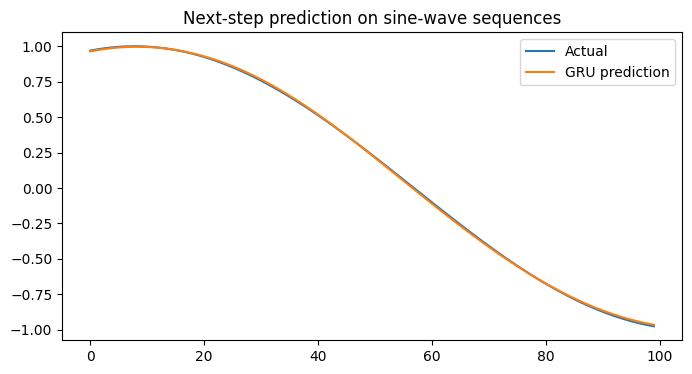

In [ ]:
# Plot a few test predictions from the GRU
gru_model.eval()
xb, yb = next(iter(seq_test_loader))
with torch.no_grad():
    pred = gru_model(xb.to(device)).cpu().numpy().flatten()
plt.figure(figsize=(8, 4))
plt.plot(yb.numpy().flatten()[:100], label="Actual")
plt.plot(pred[:100], label="GRU prediction")
plt.title("Next-step prediction on sine-wave sequences")
plt.legend()
plt.show()


In [ ]:
from torchvision import datasets, transforms, models
from torchvision.models import ResNet18_Weights

weights = ResNet18_Weights.DEFAULT
transfer_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=weights.transforms().mean, std=weights.transforms().std)
])

cifar_train = datasets.CIFAR10(root="./data", train=True, download=True, transform=transfer_transform)
cifar_test = datasets.CIFAR10(root="./data", train=False, download=True, transform=transfer_transform)

# CIFAR-10 labels: cat=3, dog=5. Keep a small balanced subset.
def cat_dog_indices(dataset, per_class=500):
    selected = []
    counts = {3: 0, 5: 0}
    for i, (_, label) in enumerate(dataset):
        if label in counts and counts[label] < per_class:
            selected.append(i)
            counts[label] += 1
        if all(v >= per_class for v in counts.values()):
            break
    return selected

train_indices = cat_dog_indices(cifar_train, per_class=400)
test_indices = cat_dog_indices(cifar_test, per_class=100)
catdog_train = Subset(cifar_train, train_indices)
catdog_test = Subset(cifar_test, test_indices)
catdog_train_loader = DataLoader(catdog_train, batch_size=32, shuffle=True)
catdog_test_loader = DataLoader(catdog_test, batch_size=64, shuffle=False)

print("Cat/dog train size:", len(catdog_train), "test size:", len(catdog_test))


100%|██████████| 170M/170M [30:42<00:00, 92.5kB/s]


Cat/dog train size: 800 test size: 200


In [ ]:
# Load pretrained ResNet18; freeze feature extractor and train the new head first.
resnet = models.resnet18(weights=weights)
for param in resnet.parameters():
    param.requires_grad = False
resnet.fc = nn.Linear(resnet.fc.in_features, 2)
resnet = resnet.to(device)

# Map original CIFAR labels: cat (3) -> 0, dog (5) -> 1
class CatDogMapped(torch.utils.data.Dataset):
    def __init__(self, subset):
        self.subset = subset
    def __len__(self):
        return len(self.subset)
    def __getitem__(self, idx):
        image, label = self.subset[idx]
        return image, (0 if label == 3 else 1)

catdog_train_mapped = CatDogMapped(catdog_train)
catdog_test_mapped = CatDogMapped(catdog_test)
catdog_train_loader = DataLoader(catdog_train_mapped, batch_size=32, shuffle=True)
catdog_test_loader = DataLoader(catdog_test_mapped, batch_size=64)

resnet, transfer_history = train_classifier(
    resnet, catdog_train_loader, catdog_test_loader, epochs=3, patience=2
)
print("Transfer-learning test accuracy:", f"{evaluate(resnet, catdog_test_loader)[1]:.2%}")


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 148MB/s]


Epoch 1/3 | train loss 0.7035 | val loss 0.5941 | val accuracy 0.655
Epoch 2/3 | train loss 0.5499 | val loss 0.5386 | val accuracy 0.700
Epoch 3/3 | train loss 0.4752 | val loss 0.5019 | val accuracy 0.730
Transfer-learning test accuracy: 73.00%


In [ ]:
!pip -q install -U transformers


In [ ]:
from transformers import pipeline

sentiment = pipeline(
    task="sentiment-analysis",
    model="distilbert/distilbert-base-uncased-finetuned-sst-2-english",
    device=0 if torch.cuda.is_available() else -1
)

samples = [
    "I really enjoyed learning deep learning in Google Colab.",
    "The model was confusing and the results were disappointing."
]
for text in samples:
    print(text)
    print(sentiment(text))
    print()


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

I really enjoyed learning deep learning in Google Colab.
[{'label': 'POSITIVE', 'score': 0.9991437196731567}]

The model was confusing and the results were disappointing.
[{'label': 'NEGATIVE', 'score': 0.999760091304779}]



In [ ]:
from transformers import pipeline

generator = pipeline(
    "text-generation",
    model="distilgpt2",
    device=0 if torch.cuda.is_available() else -1
)

prompt = "Deep learning is useful because"
result = generator(
    prompt,
    max_new_tokens=60,
    do_sample=True,
    temperature=0.8,
    pad_token_id=generator.tokenizer.eos_token_id
)
print(result[0]["generated_text"])


config.json:   0%|          | 0.00/762 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  353MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Deep learning is useful because it allows you to quickly learn more about those topics.

















































